In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# tickers = ["AAPL", "MSFT", "INTC", "GOOGL", "VZ", "DIS", "AMZN", "HD", "MCD", "PG", "KO", "WMT", "JNJ", "PFE", "UNH", "JPM", "BAC", "GS", "XOM", "CVX", "COP", "CAT", "BA", "UNP", "APD", "SHW", "NEM", "NEE", "DUK", "SO", "SPG", "PSA", "O", "^GSPC", "^VIX"]

# prices = yf.download(tickers, start="2005-01-01", end="2026-01-01", auto_adjust=True) #auto_adjust=True si split donc action passe de 200 a 100, ca ajuste tout seul pour eviter de croire a un crack
# data = prices.stack(level="Ticker", future_stack=True).reset_index() #transforme le tableau sous la forme de une ligne par jour et par action
# data.columns = [name.lower() for name in data.columns]
# data.to_csv("../data/raw/yahoo_dataset.csv", index=False)

df=pd.read_csv("../data/raw/yahoo_dataset.csv", parse_dates=["date"]) #permet de figer les données pour travailler sur la même contenu avec tom
#par defaut, pd.read_csv tranforme tout en texte, parse_date=[colonne] permet de transformer la colonne en format date pour faciliter le traitement par la suite

print(df.shape)
print("empty cells", df.isna().sum().sum())

print(df.head())

(184905, 7)
empty cells 0
        date ticker      close       high        low       open     volume
0 2005-01-03   AAPL   0.945772   0.972969   0.935461   0.968038  691992000
1 2005-01-03   AMZN   2.226000   2.272000   2.210500   2.247500  208930000
2 2005-01-03    APD  31.558720  31.803359  31.243404  31.667448     892906
3 2005-01-03     BA  35.678841  36.574836  35.643839  36.294836    3749900
4 2005-01-03    BAC  28.560421  28.861640  28.388297  28.683368   10238100


In [3]:
vix=df[df["ticker"]=="^VIX"].copy()
spx=df[df["ticker"]=="^GSPC"].copy()
stocks=df[~df["ticker"].isin(["^VIX", "^GSPC"])].copy()

stocks.head(35)

,date,ticker,close,high,low,open,volume
0,2005-01-03,AAPL,0.945772,0.972969,0.935461,0.968038,691992000
1,2005-01-03,AMZN,2.226000,2.272000,2.210500,2.247500,208930000
2,2005-01-03,APD,31.558720,31.803359,31.243404,31.667448,892906
3,2005-01-03,BA,35.678841,36.574836,35.643839,36.294836,3749900
4,2005-01-03,BAC,28.560421,28.861640,28.388297,28.683368,10238100
5,2005-01-03,CAT,28.004168,28.616861,27.848049,28.307568,6294000
6,2005-01-03,COP,15.630539,16.115567,15.593371,16.115567,8557862
7,2005-01-03,CVX,22.086277,22.767524,22.055903,22.763183,7346800
8,2005-01-03,DIS,21.923826,22.246582,21.892337,21.892337,5698936
9,2005-01-03,DUK,16.137487,16.459592,16.085950,16.375845,1296277


In [4]:
stocks=stocks.sort_values(["ticker", "date"]).reset_index(drop=True) #reorganize by ticker 
stocks.head(5)

,date,ticker,close,high,low,open,volume
0,2005-01-03,AAPL,0.945772,0.972969,0.935461,0.968038,691992000
1,2005-01-04,AAPL,0.955485,0.978348,0.940990,0.953243,1096810400
2,2005-01-05,AAPL,0.963854,0.975061,0.957129,0.963255,680433600
3,2005-01-06,AAPL,0.964601,0.969980,0.946369,0.966393,705555200
4,2005-01-07,AAPL,1.034835,1.040513,0.967589,0.971325,2227450400


In [5]:
#day volatility by Garman-Klass
def garman_klass_vol(data):
    return np.sqrt(0.5*np.log(data['high']/data['low'])**2-(2*np.log(2)-1)*np.log(data['close']/data['open'])**2)

stocks["vol"]=garman_klass_vol(stocks)
print("day with zero vol :", (stocks["vol"]==0).sum())
print(stocks["vol"].describe())

day with zero vol : 0
count    174339.000000
mean          0.012614
std           0.009079
min           0.001299
25%           0.007541
50%           0.010388
75%           0.014756
max           0.338292
Name: vol, dtype: float64


In [6]:
#HAR
#3 composantes en log : vol ajd, vol moyenne de la semaine de bourse (5 jours), vol moyenne du mois de bourse (22 jours)
stocks["log_vol_d"]=np.log(stocks["vol"])

def window_mean(vol, nb):
    return vol.rolling(nb).mean()

stocks["log_vol_w"]=np.log(stocks.groupby("ticker")["vol"].transform(window_mean, nb=5))
stocks["log_vol_m"]=np.log(stocks.groupby("ticker")["vol"].transform(window_mean, nb=22))

print(stocks[stocks["ticker"]=="AAPL"][["date", "vol", "log_vol_d", "log_vol_w", "log_vol_m"]].head(7))

        date       vol  log_vol_d  log_vol_w  log_vol_m
0 2005-01-03  0.023740  -3.740578        NaN        NaN
1 2005-01-04  0.027492  -3.593878        NaN        NaN
2 2005-01-05  0.013120  -4.333621        NaN        NaN
3 2005-01-06  0.017386  -4.052063        NaN        NaN
4 2005-01-07  0.033019  -3.410662  -3.774371        NaN
5 2005-01-10  0.027707  -3.586056  -3.740386        NaN
6 2005-01-11  0.040433  -3.208113  -3.636925        NaN


In [7]:
#more variable to see if more information than HAR allow us to predict better volatility
def log_return(price, nb):
    return np.log(price).diff(nb) #log property : log(a/b)=log(a)-lob(b)

stocks["return_d"]=stocks.groupby("ticker")["close"].transform(log_return, nb=1) #we use close bcs we predict at the end of the day -> no look ahead
stocks["return_w"]=stocks.groupby("ticker")["close"].transform(log_return, nb=5) #we predict vol at t+1 with info at the end of t

avg_volume_w=stocks.groupby("ticker")["volume"].transform(window_mean, nb=22)
stocks["log_volume_ratio"]=np.log(stocks["volume"]/avg_volume_w) #volume that day higher than the average volume of the month

stocks["day_of_week"]=stocks["date"].dt.dayofweek 

print(stocks[stocks["ticker"]=="AAPL"][["date", "return_d", "return_w", "log_volume_ratio", "day_of_week"]].head(7))

        date  return_d  return_w  log_volume_ratio  day_of_week
0 2005-01-03       NaN       NaN               NaN            0
1 2005-01-04  0.010217       NaN               NaN            1
2 2005-01-05  0.008720       NaN               NaN            2
3 2005-01-06  0.000775       NaN               NaN            3
4 2005-01-07  0.070283       NaN               NaN            4
5 2005-01-10 -0.004196  0.085799               NaN            0
6 2005-01-11 -0.065932  0.009650               NaN            1


/var/folders/6s/xtkndfwn7wjg9rldszz9vh1h0000gn/T/ipykernel_56142/329108468.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  stocks["day_of_week"]=stocks["date"].dt.dayofweek


In [8]:
vix["log_vix"]=np.log(vix["close"])
vix["vix_variation_d"]=vix["log_vix"].diff(1)
vix=vix[["date", "log_vix", "vix_variation_d"]]

spx["market_vol"]=garman_klass_vol(spx)
spx["market_log_vol_d"]=np.log(spx["market_vol"])
spx["market_log_vol_w"]=np.log(window_mean(spx["market_vol"], nb=5))
spx["market_return_d"]=np.log(spx["close"]).diff(1)
spx=spx[["date", "market_log_vol_d", "market_log_vol_w", "market_return_d"]]

stocks=stocks.merge(vix, on="date", how="left")  # left merge: keep every stock row; missing VIX data would show up as NaN
stocks=stocks.merge(spx, on="date", how="left")  # same for S&P 500 data

print("Lignes sans VIX :", stocks["log_vix"].isna().sum())
print(stocks.head())

Lignes sans VIX : 0
        date ticker     close      high       low      open      volume  \
0 2005-01-03   AAPL  0.945772  0.972969  0.935461  0.968038   691992000   
1 2005-01-04   AAPL  0.955485  0.978348  0.940990  0.953243  1096810400   
2 2005-01-05   AAPL  0.963854  0.975061  0.957129  0.963255   680433600   
3 2005-01-06   AAPL  0.964601  0.969980  0.946369  0.966393   705555200   
4 2005-01-07   AAPL  1.034835  1.040513  0.967589  0.971325  2227450400   

        vol  log_vol_d  log_vol_w  log_vol_m  return_d  return_w  \
0  0.023740  -3.740578        NaN        NaN       NaN       NaN   
1  0.027492  -3.593878        NaN        NaN  0.010217       NaN   
2  0.013120  -4.333621        NaN        NaN  0.008720       NaN   
3  0.017386  -4.052063        NaN        NaN  0.000775       NaN   
4  0.033019  -3.410662  -3.774371        NaN  0.070283       NaN   

   log_volume_ratio  day_of_week   log_vix  vix_variation_d  market_log_vol_d  \
0               NaN            0  2.644

In [9]:
def window_quantile(vol, nb, q):
    return vol.rolling(nb).quantile(q)

stocks["next_day_vol"]=stocks.groupby("ticker")["vol"].shift(-1)
stocks["threshold"]=stocks.groupby("ticker")["vol"].transform(window_quantile, nb=252, q=0.90)

stocks=stocks.dropna().copy()

stocks["target_log_vol"]=np.log(stocks["next_day_vol"])
stocks["target_spike"]=(stocks["next_day_vol"] > stocks["threshold"]).astype(int)

print("Taux de pics :", stocks["target_spike"].mean())

Taux de pics : 0.1129903688043223


In [10]:
#we drop the processing columns
features=["log_vol_d", "log_vol_w", "log_vol_m", "return_d", "return_w", "log_volume_ratio", "day_of_week", "log_vix", "vix_variation_d", "market_log_vol_d", "market_log_vol_w", "market_return_d"]
targets=["target_log_vol", "target_spike"]

data=stocks[["date", "ticker"] + features + targets]
data.to_csv("../data/processed/features.csv", index=False)

print(data.shape)
print(data["date"].min())
print(data["date"].max())
print(data.describe())

(166023, 16)
2005-12-30 00:00:00
2025-12-30 00:00:00
                             date      log_vol_d      log_vol_w  \
count                      166023  166023.000000  166023.000000   
mean   2015-12-29 12:15:18.783542      -4.523434      -4.480552   
min           2005-12-30 00:00:00      -6.645908      -5.919572   
25%           2010-12-29 00:00:00      -4.884654      -4.784769   
50%           2015-12-29 00:00:00      -4.562974      -4.529786   
75%           2020-12-28 00:00:00      -4.208722      -4.232386   
max           2025-12-30 00:00:00      -1.083844      -1.756530   
std                           NaN       0.530367       0.446647   

           log_vol_m       return_d       return_w  log_volume_ratio  \
count  166023.000000  166023.000000  166023.000000     166023.000000   
mean       -4.461101       0.000432       0.002151         -0.054373   
min        -5.628384      -0.342059      -0.815176         -3.243056   
25%        -4.737468      -0.007403      -0.015874     

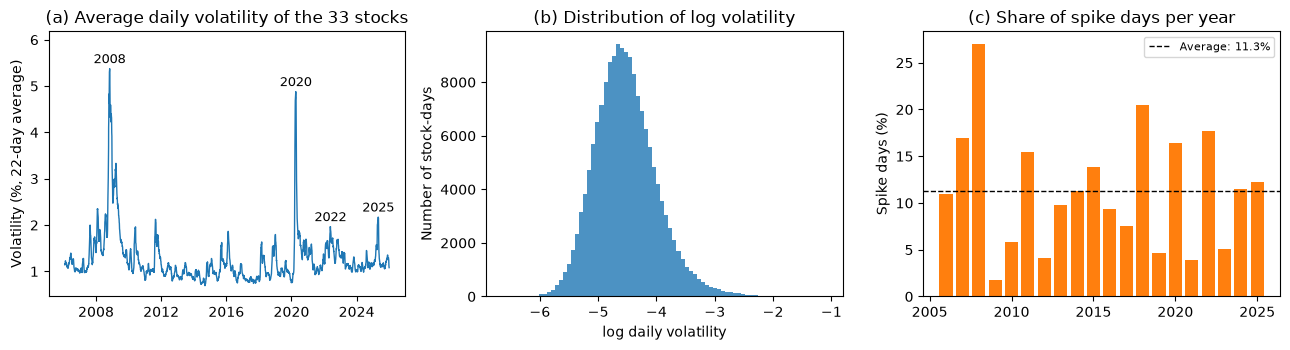

Spike rate per year (%): {2006: 10.9, 2007: 17.0, 2008: 27.0, 2009: 1.8, 2010: 5.8, 2011: 15.4, 2012: 4.1, 2013: 9.8, 2014: 11.2, 2015: 13.8, 2016: 9.4, 2017: 7.6, 2018: 20.5, 2019: 4.7, 2020: 16.4, 2021: 4.0, 2022: 17.7, 2023: 5.1, 2024: 11.5, 2025: 12.2}
Skewness raw vol: 5.09 | log vol: 0.55


In [ ]:
Path("../figures").mkdir(exist_ok=True)

data = pd.read_csv("../data/processed/features.csv", parse_dates=["date"])
data["vol_pct"] = 100 * np.exp(data["log_vol_d"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) Average daily volatility over time, 22-day smoothing
avg_vol = data.groupby("date")["vol_pct"].mean().rolling(22).mean()
axes[0].plot(avg_vol.index, avg_vol.values, color="tab:blue", linewidth=1)
for year in ["2008", "2020", "2022", "2025"]:  # label the highest point of each crisis year
    peak_day = avg_vol.loc[year].idxmax()
    axes[0].annotate(year, (peak_day, avg_vol.loc[peak_day]),
                     textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
axes[0].set_ylim(top=avg_vol.max() * 1.15)
axes[0].set_title("(a) Average daily volatility of the 33 stocks")
axes[0].set_ylabel("Volatility (%, 22-day average)")

# (b) Distribution of log volatility
axes[1].hist(data["log_vol_d"], bins=80, color="tab:blue", alpha=0.8)
axes[1].set_title("(b) Distribution of log volatility")
axes[1].set_xlabel("log daily volatility")
axes[1].set_ylabel("Number of stock-days")

# (c) Spike rate per year
years = data[data["date"].dt.year >= 2006]
spike_rate = 100 * years.groupby(years["date"].dt.year)["target_spike"].mean()
axes[2].bar(spike_rate.index, spike_rate.values, color="tab:orange")
axes[2].axhline(100 * data["target_spike"].mean(), color="black", linestyle="--", linewidth=1,
                label=f"Average: {100 * data['target_spike'].mean():.1f}%")
axes[2].set_title("(c) Share of spike days per year")
axes[2].set_ylabel("Spike days (%)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("../figures/plot.png", dpi=200)
plt.show()

print("Spike rate per year (%):", spike_rate.round(1).to_dict())
print("Skewness raw vol:", round(data["vol_pct"].skew(), 2), "| log vol:", round(data["log_vol_d"].skew(), 2))